# Introduction to Machine Learning
### Practical Homework 2
#### Sharif Uni. of Tech. - EE Dep. - 1404-2 Semester
#### Deadline: 1405-02-26


**Note**: 
- You are allowed, and also suggested, to use Numpy, Pandas, Scikit, and Matplotlib libraries, UNLESS IT IS EXPLICITLY ADVISED OTHERWISE. <br>
- Load all the dependecies of a cell inside itself, do not create inter-cell dependence for files, libraries and variables

**TA Contact info:**
- Bale: @firoozi_emad <br>
- Sharif email: emad.firoozi77@sharif.edu
- Gmail: emad.firoozi84@gmail.com

# Problem 1: Escaping Saddle Points (First-Order vs. Second-Order Methods) - 25 points

In optimization, critical points where the gradient is zero ($\nabla \mathcal{L}(\theta) = 0$) are not always local minima. They can also be local maxima or saddle points. In high-dimensional non-convex landscapes, saddle points are exponentially more common than local minima and pose a significant challenge for optimization algorithms.

In this problem, we will analyze a 2D non-convex objective function characterized by a pathological saddle point. You will implement standard Gradient Descent (GD), Momentum-based GD, and Newton's Method entirely from scratch using PyTorch's autodiff capabilities to understand how different order methods navigate this curvature.

## 1.1 The Objective Function

Consider the following loss function:
$$ \mathcal{L}(\theta_1, \theta_2) = \theta_1^2 - 2\theta_2^2 + 0.5\theta_2^4 $$

**Task:**
1. Analytically derive the gradient vector $\nabla \mathcal{L}$ and the Hessian matrix $H$. (Do this on paper; you will use this knowledge to debug your code).
2. Implement this function in PyTorch in the cell below. Your function must be able to process a batched grid of inputs for contour plotting, as well as a single `torch.Tensor` parameter vector for optimization.

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def loss_function(theta):
    # TODO: Compute objective function L(theta).
    # Must support both shape (2,) and (N, 2) tensors.
    theta_1 = theta[..., 0]
    theta_2 = theta[..., 1]
    
    loss = theta_1**2 - 2*theta_2**2 + 0.5*theta_2**4
    
    return loss

## 1.2 Implementing First-Order Methods from Scratch

First-order methods rely solely on the gradient of the objective function. 
* **Standard GD:** Updates parameters purely based on the steepest descent direction.
  $$ \theta_{t+1} = \theta_t - \eta \nabla \mathcal{L}(\theta_t) $$
* **Momentum GD:** Accumulates a velocity vector to power through narrow valleys and escape flat regions.
  $$ m_t = \beta m_{t-1} + \nabla \mathcal{L}(\theta_t) $$
  $$ \theta_{t+1} = \theta_t - \eta m_t $$

**Task:** 
Implement both GD and Momentum in the function below. You **may not** use `torch.optim`. You must use `torch.autograd.grad` or `.backward()` to compute the gradients dynamically at each step. Ensure you detach tensors or use `torch.no_grad()` appropriately when performing the parameter updates so you do not build an infinite computational graph.

In [3]:
def optimize_first_order(init_theta, method='gd', lr=0.01, momentum_beta=0.9, steps=100):
    theta = init_theta.clone().detach().requires_grad_(True)
    trajectory = [theta.detach().clone()]
    velocity = torch.zeros_like(theta)
    
    for t in range(steps):
        # TODO: Compute loss and gradient
        loss = loss_function(theta)
        loss.backward()

        with torch.no_grad():
            # TODO: Implement parameter update based on 'method' ('gd' or 'momentum')
            if method == 'gd':
                theta -= lr * theta.grad

            elif method == 'momentum':
                velocity = momentum_beta * velocity + theta.grad
                theta -= lr * velocity

            else:
                raise ValueError(f"Unknown method")
        
        # TODO: Clear gradients for next step
        theta.grad.zero_()
        
        trajectory.append(theta.detach().clone())
        
    return torch.stack(trajectory)

## 1.3 Implementing Second-Order Methods (Newton's Method)

Newton's method leverages the second-order Taylor expansion to account for the curvature of the loss landscape, utilizing the inverse of the Hessian matrix $H$.
$$ \theta_{t+1} = \theta_t - \eta H^{-1} \nabla \mathcal{L}(\theta_t) $$

*Note: We include a step size $\eta$ (often called Damped Newton's Method) to prevent drastic jumps early in optimization.*

**Task:**
Computing the Hessian in modern deep learning is computationally prohibitive, but trivial for a 2D problem. Use `torch.autograd.functional.hessian` (or compute the Jacobian of the gradient manually) to implement Newton's Method.

In [4]:
def optimize_newton(init_theta, lr=0.1, steps=100):
    theta = init_theta.clone().detach().requires_grad_(True)
    trajectory = [theta.detach().clone()]
    
    # Hint: torch.autograd.functional.hessian expects a Python function as input, 
    # not a tensor. You can define a quick lambda or helper function here:
    eval_loss = lambda x: loss_function(x)
    
    for t in range(steps):
        # TODO: Compute gradient and Hessian
        loss = loss_function(theta)
        loss.backward()
        grad = theta.grad.clone()
        
        theta_detached = theta.detach()
        H = torch.autograd.functional.hessian(eval_loss, theta_detached)
        
        with torch.no_grad():
            # TODO: Compute Newton step H^{-1}g and update theta
            H_inv = torch.linalg.inv(H)
            newton_step = H_inv @ grad
            theta -= lr * newton_step
        
        # TODO: Clear gradients
        theta.grad.zero_()
        
        trajectory.append(theta.detach().clone())
        
    return torch.stack(trajectory)

## 1.4 Execution & Visualization

It is time to test your algorithms. 
The origin $(0,0)$ is a strict saddle point for our function. If we initialize exactly at zero, the gradients will be zero, and the optimizer will not move. Therefore, we will initialize **very close** to the saddle point, adding a tiny perturbation: $\theta_{init} = (0.01, 0.01)$.

**Task:**
1. Run all three optimizers for `150` steps.
   * `lr=0.01` for GD.
   * `lr=0.01`, `beta=0.9` for Momentum.
   * `lr=0.1` for Newton's Method.
2. Complete the plotting code to overlay the trajectories on a 2D contour map of the loss landscape.

GD final position: [4.8296023e-04 1.3261616e+00]
Momentum final position: [1.5544438e-06 1.4152453e+00]
Newton final position: [1.3689146e-09 1.3688346e-09]


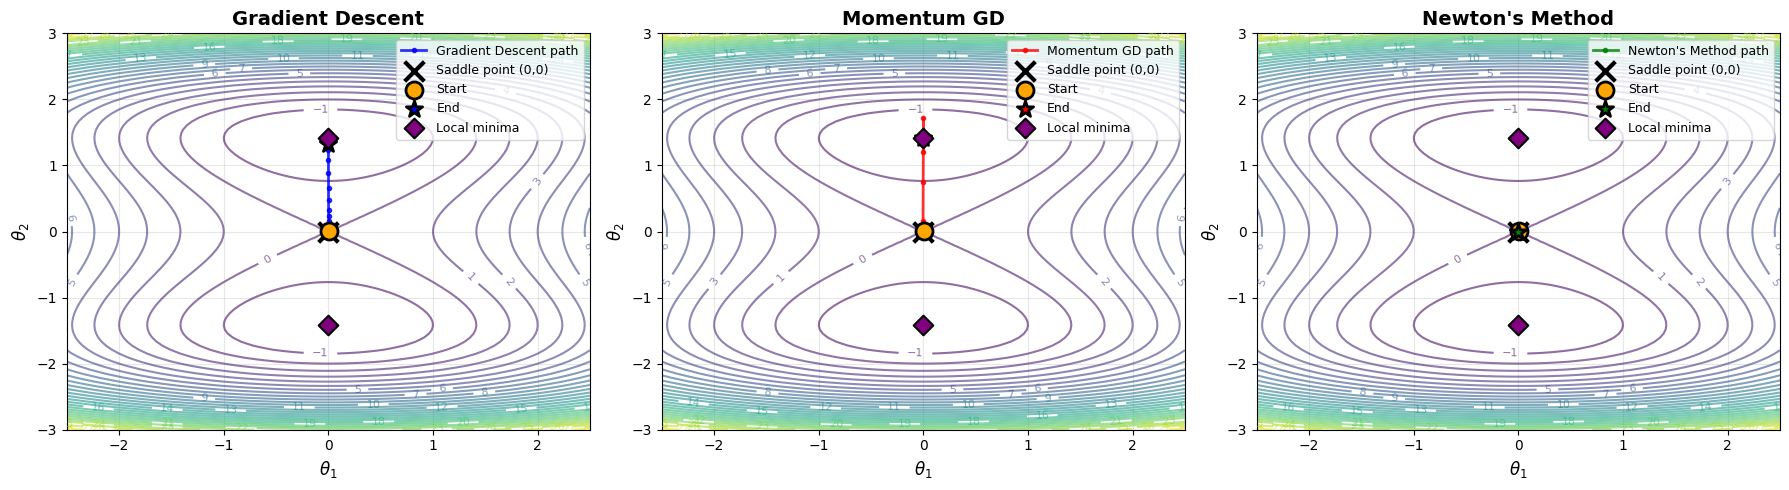

In [6]:
init_theta = torch.tensor([0.01, 0.01])

# TODO: Execute optimizations for GD, Momentum, and Newton's Method


traj_gd = optimize_first_order(init_theta, method='gd', lr=0.01, steps=150)
traj_momentum = optimize_first_order(init_theta, method='momentum', lr=0.01, momentum_beta=0.9, steps=150)
traj_newton = optimize_newton(init_theta, lr=0.1, steps=150)

print(f"GD final position: {traj_gd[-1].numpy()}")
print(f"Momentum final position: {traj_momentum[-1].numpy()}")
print(f"Newton final position: {traj_newton[-1].numpy()}")

# Visualization Setup
grid_x, grid_y = torch.meshgrid(torch.linspace(-2.5, 2.5, 100), torch.linspace(-3, 3, 100), indexing='ij')
grid_theta = torch.stack([grid_x.flatten(), grid_y.flatten()], dim=1)

# TODO: Calculate grid_z = loss_function(grid_theta) and reshape it to (100, 100)

grid_z = loss_function(grid_theta).reshape(100, 100)

# TODO: Plot the contour map and overlay the three trajectories.
# HINT to prevent overlapping paths:
# 1. Use plt.subplots(1, 3) to create a separate plot for each method, OR
# 2. Use distinct linestyles (e.g., linestyle='--', linewidth=2), markers, and high-contrast colors.
# 3. Clearly mark the saddle point at (0,0) and the final position of each optimizer.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

methods = [
    ('Gradient Descent', traj_gd, 'blue'),
    ('Momentum GD', traj_momentum, 'red'),
    ('Newton\'s Method', traj_newton, 'green')
]

for ax, (method_name, trajectory, color) in zip(axes, methods):
    contour = ax.contour(grid_x.numpy(), grid_y.numpy(), grid_z.numpy(), levels=30, cmap='viridis', alpha=0.6)
    ax.clabel(contour, inline=True, fontsize=8)
    
    traj_np = trajectory.numpy()
    ax.plot(traj_np[:, 0], traj_np[:, 1], color=color, linewidth=2, marker='o', 
            markersize=3, markevery=10, label=f'{method_name} path', alpha=0.8)
    
    ax.scatter(0, 0, color='black', s=200, marker='x', linewidths=3, label='Saddle point (0,0)', zorder=5)
    

    ax.scatter(traj_np[0, 0], traj_np[0, 1], color='orange', s=150, marker='o', edgecolors='black', linewidths=2, label='Start', zorder=5)
    
    ax.scatter(traj_np[-1, 0], traj_np[-1, 1], color=color, s=150, marker='*', edgecolors='black', linewidths=2, label='End', zorder=5)
    
    sqrt2 = np.sqrt(2)
    ax.scatter([0, 0], [sqrt2, -sqrt2], color='purple', s=100, marker='D', edgecolors='black', linewidths=1.5, label='Local minima', zorder=5)
    
    ax.set_xlabel(r'$\theta_1$', fontsize=12)
    ax.set_ylabel(r'$\theta_2$', fontsize=12)
    ax.set_title(f'{method_name}', fontsize=14, fontweight='bold')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-3, 3)

plt.tight_layout()
plt.show()

## 1.5 Analytical Questions

Based on your mathematical derivations and the observed trajectories in the plot above, answer the following questions:

**Question 1:** Analyze the trajectory of Vanilla GD vs. Momentum. Why does vanilla Gradient Descent struggle to escape the saddle point efficiently, and mathematically, how does the momentum term $\beta m_{t-1}$ alter the gradient vector to accelerate the escape?

*Vanilla GD struggles because the local gradient magnitude approaches zero near the saddle point, resulting in vanishingly small update steps.*

*Momentum overcomes this by accumulating historical gradient information through the velocity term $\beta m_{t-1}$.*

*Mathematically, consistent small gradients along the escape direction compound over time via this exponential moving average.*

*This accumulated momentum heavily outweighs the near-zero current gradient, accelerating the optimizer away from the flat region.*

**Question 2:** Observe the trajectory of Newton's Method. You should notice that it behaves very strangely (and likely moves in the completely wrong direction) when initialized near this specific saddle point. 
Evaluate the Hessian matrix exactly at the point $(0,0)$. Is it positive-definite, negative-definite, or indefinite? Based on its eigenvalues, explain *why* Newton's method fails to minimize the function in this region and instead gets attracted to a local maximum along one of the axes. 

*At the saddle point (0,0), the Hessian matrix is indefinite, possessing both positive and negative eigenvalues(2 , -4).*

*Newton’s method update relies on $H^{-1} \nabla \mathcal{L}(\theta_t)$ , which mathematically assumes the function is locally a convex paraboloid.*

*Along the axis with negative curvature (negative eigenvalue), multiplying by $H^{-1}$ inverts the natural descent direction.*

*Instead of minimizing, this sign flip forces the optimizer to ascend the gradient, attracting it toward a local maximum along that specific axis.*

# Problem 2: Implementing the Armijo-Goldstein Line Search - 25 points

In standard Gradient Descent, choosing a constant step size (learning rate $\eta$) is notoriously difficult. If $\eta$ is too large, the optimizer will overshoot the minimum and diverge; if it is too small, convergence takes an excruciatingly long time. 

To solve this, we use **Line Search** algorithms to dynamically compute the optimal step size at every iteration. In this problem, you will implement the **Armijo-Goldstein Backtracking Line Search** and test it on a notoriously difficult landscape: a poorly scaled (ill-conditioned) quadratic function.

## 2.1 The Mathematics of Armijo-Goldstein

Recall from the lecture slides that the sequence of step sizes $\{\eta_t\}$ can be determined dynamically. 
Let $d_t$ be our descent direction (for standard GD, $d_t = -g_t = -\nabla \mathcal{L}(\theta_t)$). 
Let $m = \langle \nabla \mathcal{L}(\theta_t), d_t \rangle$.

We choose an initial large learning rate $\eta_0$, a control parameter $c \in (0,1)$, and a decay factor $\tau \in (0,1)$. We then repeatedly decay the learning rate ($\eta \leftarrow \tau \eta$) until the following condition is met:

$$ \mathcal{L}(\theta_t + \eta d_t) \leq \mathcal{L}(\theta_t) + c \eta m $$

**Task:**
Familiarize yourself with this condition. Notice that because $d_t$ is a descent direction, $m$ is negative. This inequality ensures we achieve a *sufficient decrease* in the loss function relative to the step size we are taking.

## 2.2 The Ill-Conditioned Landscape

To demonstrate why line search is necessary, we will optimize an extremely "stretched" or ill-conditioned quadratic function. 

$$ \mathcal{L}(\theta) = \frac{1}{2} \theta^T Q \theta $$

where $Q = \begin{bmatrix} 100 & 0 \\ 0 & 1 \end{bmatrix}$. 

**Task:** Implement this loss function below.

In [7]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def ill_conditioned_loss(theta):
    # TODO: Compute ill-conditioned quadratic loss using Q matrix.
    Q = torch.tensor([[100.0, 0.0], 
                      [0.0, 1.0]], dtype=theta.dtype, device=theta.device)
    
    if theta.dim() == 1:
        loss = 0.5 * theta @ Q @ theta

    else:
        loss = 0.5 * (theta @ Q * theta).sum(dim=-1)
    
    return loss

## 2.3 Implementing the Armijo-Goldstein Optimizer

You will now write a custom optimization loop. At every epoch, instead of taking a step with a fixed learning rate, you must compute the search direction, execute the backtracking `while` loop until the Armijo condition is satisfied, and *then* update the parameters.

**Task:**
Complete the `optimize_armijo` function. 

*Hint: Evaluating $\mathcal{L}(\theta_t + \eta d_t)$ requires calculating the loss at a hypothetical new position. Do this without breaking your PyTorch computation graph, or use `.detach()` appropriately so you do not accumulate massive memory overhead during the `while` loop.*

In [8]:
def optimize_armijo(init_theta, max_steps=100, eta_init=1.0, c=0.1, tau=0.5):
    theta = init_theta.clone().detach().requires_grad_(True)
    trajectory = [theta.detach().clone()]
    losses = []
    total_evals = 0
    
    for t in range(max_steps):
        loss = ill_conditioned_loss(theta)
        losses.append(loss.item())
        total_evals += 1
        
        # TODO: Compute gradient and descent direction (d_t)
        loss.backward()
        d_t = -theta.grad.detach()
        m = (theta.grad.detach() * d_t).sum()

        with torch.no_grad():
            # TODO: Implement Backtracking Line Search (while loop).
            eta = eta_init
            loss_curr = loss.detach()
            
            while True:
                theta_new = theta + eta * d_t
                loss_new = ill_conditioned_loss(theta_new).detach()
                total_evals += 1
                
                if loss_new <= loss_curr + c * eta * m:
                    break
                eta *= tau
            # TODO: Update parameters theta
            theta = theta_new.detach().requires_grad_(True)

            
        # TODO: Clear gradients
        if theta.grad is not None:
            theta.grad.zero_()
        
        trajectory.append(theta.detach().clone())
        
    return losses, torch.stack(trajectory), total_evals

## 2.4 Comparison: Constant LR vs. Armijo-Goldstein

Let's put your dynamic learning rate to the test against a standard fixed-rate approach. 

**Task:**
1. Implement a quick, standard GD loop with a constant learning rate of $\eta = 0.015$ (which is dangerously close to the theoretical divergence limit for this specific $Q$ matrix).
2. Run both your `optimize_armijo` and the standard GD from the starting point $\theta_{init} = (8.0, 8.0)$ for $50$ steps.
3. Plot the **Loss vs. Step** curve for both methods on the same graph to compare convergence speed.

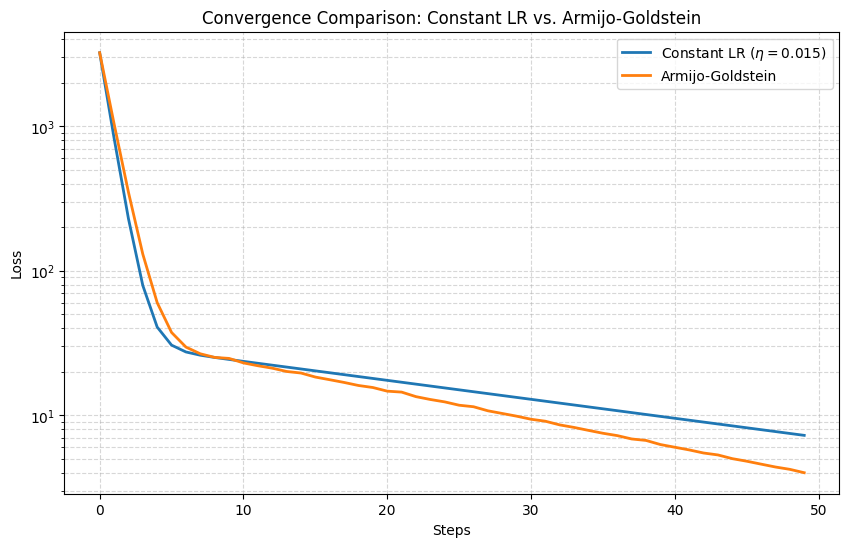

Constant LR - Final Loss: 7.2761, Total function evaluations: 50
Armijo - Final Loss: 4.0125, Total function evaluations: 382


In [9]:
def optimize_constant_lr(init_theta, lr=0.015, steps=50):
    theta = init_theta.clone().detach().requires_grad_(True)
    losses = []
    total_evals = 0
    
    # TODO: Standard GD loop tracking losses and total_evals
    for _ in range(steps):
        loss = ill_conditioned_loss(theta)
        losses.append(loss.item())
        total_evals += 1
        
        loss.backward()
        
        with torch.no_grad():
            theta -= lr * theta.grad
            
        theta.grad.zero_()
    
    return losses, total_evals

init_theta = torch.tensor([8.0, 8.0])

# TODO: Run both optimizers
losses_const, evals_const = optimize_constant_lr(init_theta, lr=0.015, steps=50)
losses_armijo, traj_armijo, evals_armijo = optimize_armijo(init_theta, max_steps=50)

# TODO: Plot Loss vs Steps for both methods. 

plt.figure(figsize=(10, 6))
plt.plot(losses_const, label='Constant LR ($\eta = 0.015$)', linewidth=2)
plt.plot(losses_armijo, label='Armijo-Goldstein', linewidth=2)

plt.xlabel('Steps')
plt.ylabel('Loss')
plt.title('Convergence Comparison: Constant LR vs. Armijo-Goldstein')
plt.yscale('log') 
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.show()

print(f"Constant LR - Final Loss: {losses_const[-1]:.4f}, Total function evaluations: {evals_const}")
print(f"Armijo - Final Loss: {losses_armijo[-1]:.4f}, Total function evaluations: {evals_armijo}")

## 2.5 Analytical Questions

**Question 1:** Look at the print statements for the "Total Loss Function Evaluations." While the Armijo-Goldstein method likely converged in fewer *outer* steps, what is the hidden computational trade-off of using a line search method compared to standard SGD? When might this trade-off be unacceptable in modern Machine Learning?

*The hidden trade-off is the extra computational cost of evaluating the loss function repeatedly during the backtracking loop to find an acceptable step size. While taking fewer outer steps, it demands multiple forward passes per update, drastically increasing the total function evaluations. This is unacceptable in modern Deep Learning because running multiple forward passes on massive neural networks and huge datasets for a single gradient update is computationally prohibitive and entirely inefficient compared to cheap, single-pass mini-batch SGD.*

**Question 2:** If you ran the constant learning rate at $\eta = 0.05$, it would completely explode (diverge to infinity) on this ill-conditioned matrix. Explain geometrically *why* a fixed learning rate fails so spectacularly on matrices where the eigenvalues are vastly different in magnitude (like our $Q$ matrix), and how the Armijo condition mathematically prevents this explosion.

*Geometrically, ill-conditioned matrices create steep, narrow ravines where the gradient points almost perpendicularly across the ravine walls rather than towards the minimum. A large fixed learning rate like η=0.05 causes the update to wildly overshoot the opposite wall, bouncing higher and higher in a divergent oscillation. The Armijo condition mathematically prevents this because any step that overshoots will result in a higher loss, failing the $ \mathcal{L}(\theta_t + \eta d_t) \leq \mathcal{L}(\theta_t) + c \eta m $
 inequality and forcing the step size to decay until a strict decrease is achieved.*

# Problem 3: Expanding Model Capacity (Closing the KL-Divergence Gap) - 25 points

If we restrict a probabilistic model to a **diagonal covariance matrix**, it assumes that our variables $\theta_1$ and $\theta_2$ are entirely independent. While such a model might successfully learn the target mean and marginal variances, it will fail to align perfectly with a target distribution that contains off-diagonal correlations (which visually appears as a tilted contour).

To drive the KL divergence to zero and capture these correlations, we must expand our model's capacity by learning a **full covariance matrix** $\Sigma$.

## 3.1 The Mathematics of Positive Semi-Definiteness

A valid covariance matrix must be symmetric and positive semi-definite (PSD). If we simply learn a $2 \times 2$ matrix of free parameters, the optimization process will quickly push it into non-PSD territory, leading to negative variances or complex numbers, and the simulation will crash.

**Task:**
To guarantee that our learned matrix $\Sigma$ is always PSD, we will use the **Cholesky Decomposition**. Any real positive-definite matrix $\Sigma$ can be factored into:
$$ \Sigma = L L^T $$
where $L$ is a lower-triangular matrix with strictly positive diagonal entries.

Instead of learning $\Sigma$ directly, your model will learn the non-zero elements of $L$:
$$ L = \begin{bmatrix} l_{11} & 0 \\ l_{21} & l_{22} \end{bmatrix} $$

*Note: To ensure $l_{11} > 0$ and $l_{22} > 0$ during unconstrained gradient descent, you should pass the learned diagonal parameters through a strictly positive function (like `torch.exp` or `torch.nn.functional.softplus`).*

In [9]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math

target_mean = torch.tensor([2.0, -1.0], dtype=torch.float32)
target_cov = torch.tensor([[2.0, 1.5], [1.5, 2.5]], dtype=torch.float32)

def build_covariance_matrix(l_params):
    # l_params indices: [unconstrained l_11, l_21, unconstrained l_22]
    # Hint: Start by initializing an empty 2x2 matrix, e.g., L = torch.zeros((2, 2))
    # TODO: Apply softplus/exp to diagonals, construct lower triangular L, compute Sigma

    L = torch.zeros((2, 2), dtype=l_params.dtype, device=l_params.device)
    L[0, 0] = F.softplus(l_params[0]) 
    L[1, 0] = l_params[1]              
    L[1, 1] = F.softplus(l_params[2]) 

    Sigma = L @ L.T
    
    return Sigma, L

## 3.2 Multivariate KL-Divergence from Scratch

Previously, we used a simplified KL-divergence formula for diagonal matrices. Now, you must implement the general formula for two multivariate normal distributions $\mathcal{N}_q(\mu_q, \Sigma_q)$ and $\mathcal{N}_p(\mu_p, \Sigma_p)$ of dimension $k$:

$$ D_{KL}(Q || P) = \frac{1}{2} \left[ \log \frac{|\Sigma_p|}{|\Sigma_q|} - k + \text{Tr}(\Sigma_p^{-1} \Sigma_q) + (\mu_p - \mu_q)^T \Sigma_p^{-1} (\mu_p - \mu_q) \right] $$

**Task:**
Implement this mathematical formula using PyTorch tensor operations. Do not use `torch.distributions.kl.kl_divergence` for this step; you must compute it manually to demonstrate your understanding of the linear algebra.

In [10]:
def kl_divergence_full(mu_q, Sigma_q, mu_p, Sigma_p):
    k = mu_q.shape[0]
    
    # TODO: Implement exact KL divergence formula
    log_det_term = torch.logdet(Sigma_p) - torch.logdet(Sigma_q)
    trace = torch.trace(torch.linalg.inv(Sigma_p) @ Sigma_q)
    mahalanobis = (mu_p - mu_q) @ torch.linalg.inv(Sigma_p) @ (mu_p - mu_q)

    kl_div = 0.5 * (log_det_term - k + trace + mahalanobis)
    
    return kl_div

## 3.3 Optimization with Adam

Now that you have defined the computational graph for building a valid full covariance matrix and calculating the analytical loss, it is time to optimize.

**Task:**
1. Initialize the learnable parameters: a 2-element tensor for $\mu$ and a 3-element tensor for the components of $L$.
2. Initialize the `Adam` optimizer.
3. Write the training loop to minimize the exact KL divergence.

In [14]:
from torch.optim import Adam

# TODO: Initialize mu and l_params (requires_grad=True)
mu = torch.zeros(2, requires_grad=True)  
l_params = torch.tensor([1.0, 0.0, 1.0], requires_grad=True)

# TODO: Initialize Adam optimizer
optimizer = Adam([mu, l_params], lr=0.01)

steps = 300
losses = []

for step in range(steps):
    # TODO: 
    # 1. Zero grad
    # 2. Build Sigma_q from l_params
    # 3. Compute loss using kl_divergence_full
    # 4. Backprop and step

    optimizer.zero_grad()

    Sigma_q, _ = build_covariance_matrix(l_params)

    loss = kl_divergence_full(mu, Sigma_q, target_mean, target_cov)
    
    loss.backward()
    optimizer.step()
    
    losses.append(loss.item())
    
    if (step + 1) % 50 == 0:
        print(f"Step {step + 1}/{steps}, KL Divergence: {loss.item():.6f}")
    

# TODO: Print final results comparing learned mu/Sigma against target_mean/target_cov

with torch.no_grad():
    final_Sigma_q, _ = build_covariance_matrix(l_params)
    final_kl = kl_divergence_full(mu, final_Sigma_q, target_mean, target_cov)

print("\nLearned Mean:")
print(mu.detach().numpy())
print("\nTarget Mean:")
print(target_mean.numpy())
print("\nMean Error (L2):", torch.norm(mu - target_mean).item())

print("\nLearned Covariance Matrix:")
print(final_Sigma_q.detach().numpy())
print("\nTarget Covariance Matrix:")
print(target_cov.numpy())
print("\nCovariance Frobenius Error:", torch.norm(final_Sigma_q - target_cov, 'fro').item())

print(f"\nFinal KL Divergence: {final_kl.item():.8f}")

Step 50/300, KL Divergence: 1.716880
Step 100/300, KL Divergence: 0.713787
Step 150/300, KL Divergence: 0.273229
Step 200/300, KL Divergence: 0.109814
Step 250/300, KL Divergence: 0.054873
Step 300/300, KL Divergence: 0.034340

Learned Mean:
[ 1.6348017 -1.3184483]

Target Mean:
[ 2. -1.]

Mean Error (L2): 0.48454007506370544

Learned Covariance Matrix:
[[1.9954056 1.4932678]
 [1.4932678 2.4924915]]

Target Covariance Matrix:
[[2.  1.5]
 [1.5 2.5]]

Covariance Frobenius Error: 0.012966590002179146

Final KL Divergence: 0.03406754


## 3.4 Verification and Visualization

If your math and implementation are correct, your loss should smoothly approach a value very close to zero, and your learned covariance matrix should be nearly identical to the target.

Run the cell below to plot the final contours. You should see the learned distribution perfectly overlapping the tilted ellipses of the target distribution.

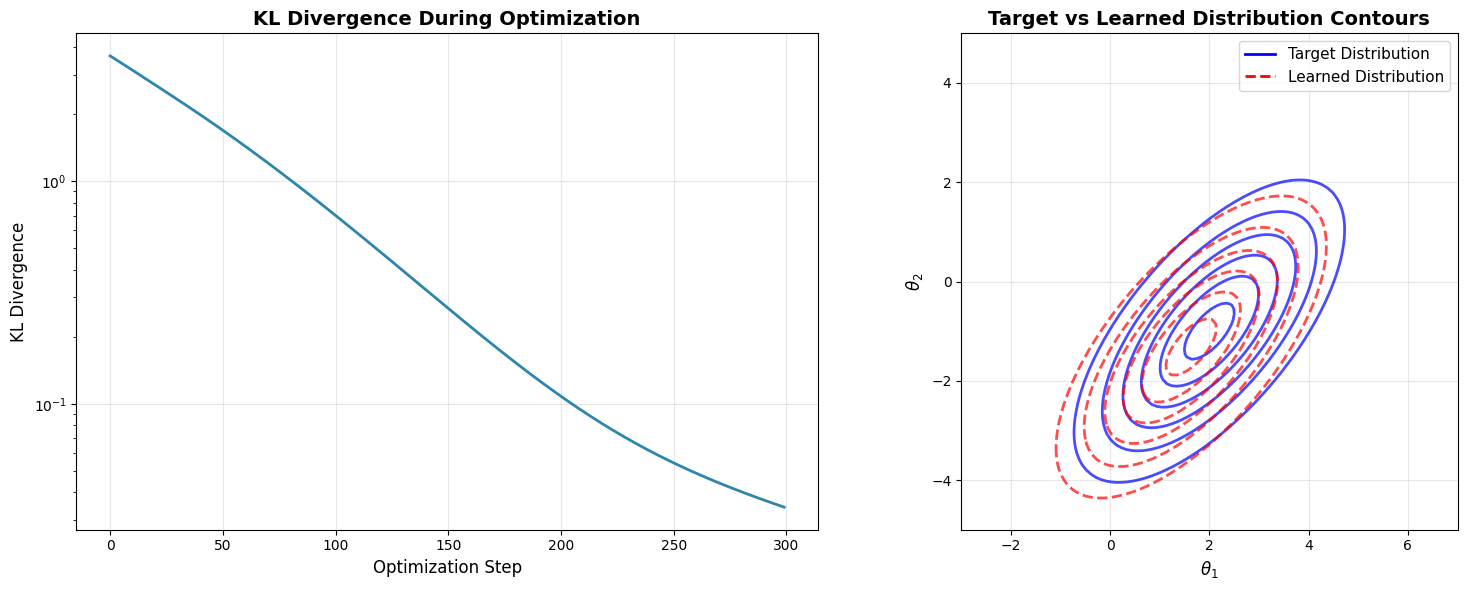

In [15]:
# Create grid for plotting
x, y = torch.meshgrid(torch.linspace(-3, 7, 100), torch.linspace(-5, 5, 100), indexing='ij')
grid = torch.stack([x.flatten(), y.flatten()], dim=-1)

# Compute target PDF
target_dist = torch.distributions.MultivariateNormal(target_mean, target_cov)
target_pdf = target_dist.log_prob(grid).exp().reshape(100, 100)

# TODO: Construct the learned MultivariateNormal distribution using your final mu and Sigma. 
# Calculate its PDF over the grid.
# learned_pdf = ...

with torch.no_grad():
    final_Sigma_q , _ = build_covariance_matrix(l_params)
    learned_dist = torch.distributions.MultivariateNormal(mu, final_Sigma_q)
    learned_pdf = learned_dist.log_prob(grid).exp().reshape(100, 100)

# TODO: Plot the Loss Curve side-by-side with the Overlaid Contours.

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Loss curve
axes[0].plot(losses, linewidth=2, color='#2E86AB')
axes[0].set_xlabel('Optimization Step', fontsize=12)
axes[0].set_ylabel('KL Divergence', fontsize=12)
axes[0].set_title('KL Divergence During Optimization', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].set_yscale('log')

# Overlaid contours
axes[1].contour(x.numpy(), y.numpy(), target_pdf.numpy(), levels=8, colors='blue', linewidths=2, linestyles='solid', alpha=0.7)
axes[1].contour(x.numpy(), y.numpy(), learned_pdf.numpy(), levels=8, colors='red', linewidths=2, linestyles='dashed', alpha=0.7)

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='blue', linewidth=2, linestyle='solid', label='Target Distribution'),
    Line2D([0], [0], color='red', linewidth=2, linestyle='dashed', label='Learned Distribution')
]
axes[1].legend(handles=legend_elements, loc='upper right', fontsize=11)

axes[1].set_xlabel('$\\theta_1$', fontsize=12)
axes[1].set_ylabel('$\\theta_2$', fontsize=12)
axes[1].set_title('Target vs Learned Distribution Contours', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].set_aspect('equal')

plt.tight_layout()
plt.show()

## 3.5 Analytical Questions

**Question 1:** In standard neural network training, we rarely parameterize the output to be a full covariance matrix, and instead assume a diagonal matrix (e.g., in standard Variational Autoencoders). Discuss the computational complexity scaling of learning a full covariance matrix $\Sigma$ via Cholesky decomposition if the dimensionality of your data $k$ was 1,000 instead of 2. 

*Learning a full covariance matrix Σ of dimension k×k via its Cholesky decomposition introduces substantial computational overhead compared to a diagonal approximation. For k=2, the storage is O(4) and the Cholesky factorization costs O(2^3/3)≈2.7 floating‑point operations, which is trivial. However, when k=1000, the full covariance matrix contains about 500000 unique entries(K*(K+1)/2) (since it is symmetric), and computing its Cholesky factor requires O(k^3/3)≈3.3×10^8 operations. Moreover, each training step that updates L and re‑computes likelihoods or KL divergences would incur this cubic cost, making the approach impractical for high‑dimensional data. In contrast, a diagonal covariance only needs O(k) parameters and operations, scaling linearly with k. Thus, the leap from k=2 to k=1000 turns a negligible cost into a prohibitive one, explaining why diagonal approximations are standard in practice.*

**Question 2:** Look closely at the KL Divergence formula you implemented. It requires calculating both the determinant and the inverse of the target matrix $\Sigma_p$. Why is ensuring positive-definiteness (through the Cholesky factor $L$) strictly necessary for this computation to be mathematically valid?

*The Kullback‑Leibler divergence contains terms $\log {|\Sigma_p|}$ and $\Sigma_p^{-1}$, For these to be mathematically well‑defined, $\Sigma_p$ must be positive definite. Positive‑definiteness guarantees that ${|\Sigma_p|} > 0 $ so its logarithm is finite and real, and that $\Sigma_p$ is invertible, so $\Sigma_p^{-1}$ exists uniquely. If $\Sigma_p$ were only positive semidefinite (singular), its determinant would be zero, making $\log {|\Sigma_p|}$ =−∞ and the inverse undefined. Indefinite matrices would give a negative determinant (invalid for a real covariance) and also break invertibility when singular. By parameterizing $\Sigma_p$ via a Cholesky factor L (with positive diagonal entries), we explicitly enforce positive‑definiteness throughout training, ensuring every intermediate covariance matrix yields a finite, real KL divergence and that all required matrix operations are numerically stable and mathematically valid.*

# Problem 4: Computational KKT Conditions & Penalty Methods - 25 points

In standard PyTorch optimization, we use unconstrained solvers like SGD or Adam. However, real-world problems often have strict physical, structural, or budget constraints. In this final problem, we will solve a constrained optimization problem twice: first analytically using the Karush–Kuhn–Tucker (KKT) conditions, and second computationally using the Exterior Penalty Method.

## 4.1 Analytical KKT Derivation

Consider the following constrained optimization problem:

$$ \min_{\theta_1, \theta_2} \mathcal{L}(\theta_1, \theta_2) = (\theta_1 - 2)^2 + 2(\theta_2 - 1)^2 $$

Subject to:
1.  **Equality Constraint:** $h(\theta_1, \theta_2) = \theta_1 + 2\theta_2 - 3 = 0$
2.  **Inequality Constraint:** $g(\theta_1, \theta_2) = \theta_1^2 + \theta_2 - 2 \le 0$

**Task:**
Use Markdown and LaTeX in the space below to solve this problem analytically.
1.  Write out the generalized Lagrangian $L(\theta, \mu, \lambda)$.
2.  Write out the four KKT conditions: Stationary point, Feasibility, Dual feasibility, and Complementary Slackness.
3.  Solve for the optimal parameters $\theta^* = (\theta_1^*, \theta_2^*)$ and the dual variables $\mu^*$ and $\lambda^*$. 

*(Hint: Check cases based on complementary slackness. Is the inequality constraint active or inactive at the optimum?)*

**Write your analytical KKT derivation here. Double click to edit.**

*   **Generalized Lagrangian:** $L(\theta_1,\theta_2,\mu,\lambda)=(\theta_1-2)^2+2(\theta_2-1)^2+\mu(\theta_1^2+\theta_2-2)+\lambda(\theta_1+2\theta_2-3).$

*   **Stationary Point Condition:** 
   \begin{aligned}
   \frac{\partial L}{\partial\theta_1}&=2(\theta_1-2)+2\mu\theta_1+\lambda = 0,\\
   \frac{\partial L}{\partial\theta_2}&=4(\theta_2-1)+\mu+2\lambda = 0.
   \end{aligned}

*   **Feasibility Condition:** 
    \begin{aligned}
   \theta_1^2+\theta_2-2\le 0,\qquad \theta_1+2\theta_2-3=0.
    \end{aligned}
   
*   **Dual Feasibility Condition:** 
    \begin{aligned}
    \mu\ge 0.
    \end{aligned}

*   **Complementary Slackness:** 
    \begin{aligned}
    \mu(\theta_1^2+\theta_2-2)=0.
    \end{aligned}

*   **Final Solution ($\theta^*, \mu^*, \lambda^*$):** 
We consider two cases.

Case 1: Inequality inactive $(\mu=0)$

Stationarity becomes  
\begin{aligned}
2(\theta_1-2)+\lambda=0 \;\Longrightarrow\; \lambda = 4-2\theta_1,
\end{aligned}

\begin{aligned}
4(\theta_2-1)+2\lambda=0 \;\Longrightarrow\; \lambda = 2-2\theta_2.
\end{aligned} 

Equating: 

\begin{aligned}
(4-2\theta_1 = 2-2\theta_2 \Rightarrow \theta_1-\theta_2=1). 
\end{aligned} 

Using the equality constraint $(\theta_1+2\theta_2=3)$:  

Substitute $(\theta_1=\theta_2+1)$ gives $((\theta_2+1)+2\theta_2=3 \Rightarrow 3\theta_2=2 \Rightarrow \theta_2=2/3,\ \theta_1=5/3)$. 
 
Check inequality: $((25/9)+(2/3)-2 = 13/9 >0)$, violating $(g\le0)$. Hence **infeasible**.

Case 2: Inequality active $\theta_1^2+\theta_2-2=0$

Then $(\theta_2 = 2-\theta_1^2)$. Substituting into the equality constraint:  

\begin{aligned}
\theta_1+2(2-\theta_1^2)=3 \;\Longrightarrow\; -2\theta_1^2+\theta_1+1=0 \;\Longrightarrow\; 2\theta_1^2-\theta_1-1=0.
\end{aligned}

Solving: $((2\theta_1+1)(\theta_1-1)=0)$ gives $(\theta_1=1)$ or $(\theta_1=-1/2)$.

* **Subcase 2a:** $(\theta_1=1)$ and $(\theta_2=1)$.  

  Stationarity equations:  
 
  \begin{aligned}
  &2(1-2)+2\mu(1)+\lambda = -2+2\mu+\lambda = 0 \quad\Rightarrow\quad \lambda = 2-2\mu,\\
  &4(1-1)+\mu+2\lambda = \mu+2\lambda = 0.
  \end{aligned}

  Substitute $(\lambda)$: $(\mu+2(2-2\mu) = 4-3\mu =0 \Rightarrow \mu = \frac{4}{3})$
     
  Then $(\lambda = 2-2\cdot\frac{4}{3}= -\frac{2}{3}).$  

  Dual feasibility: $(\mu=\frac{4}{3}\ge0)$ satisfied.

* **Subcase 2b:** $(\theta_1=-\frac{1}{2})$ and $(\theta_2=2-\frac{1}{4}=\frac{7}{4})$.  

  Stationarity:  

  \begin{aligned}
  &2\left(-\frac{1}{2}-2\right)+2\mu\left(-\frac{1}{2}\right)+\lambda = 2\left(-\frac{5}{2}\right)-\mu+\lambda = -5-\mu+\lambda=0 \;\Rightarrow\; \lambda = 5+\mu,\\
  &4\left(\frac{7}{4}-1\right)+\mu+2\lambda = 4\cdot\frac{3}{4}+\mu+2\lambda = 3+\mu+2\lambda =0.
  \end{aligned}

  Substitute $(\lambda)$: $(3+\mu+2(5+\mu)=3+\mu+10+2\mu=13+3\mu=0 \Rightarrow \mu=-\frac{13}{3}).$

  Dual feasibility fails $(\mu<0)$, so this candidate is discarded.

### Final solution

The only KKT point is  

\begin{aligned}
\boxed{\theta_1^*=1,\quad \theta_2^*=1,\quad \mu^*=\frac{4}{3},\quad \lambda^*=-\frac{2}{3}}.
\end{aligned}

The objective value is $((\theta_1-2)^2+2(\theta_2-1)^2 = (1-2)^2+2(0)^2 = 1).$

Because the problem is convex (quadratic objective, convex inequality, linear equality), this point is the global minimum.

## 4.2 The Exterior Penalty Method

Since standard autograd optimizers cannot natively "wall off" regions of the parameter space, we must modify our loss landscape. The **Exterior Penalty Method** converts a constrained problem into a sequence of unconstrained problems.

We define a penalized objective function:
$$ \mathcal{L}_{penalty}(\theta, \rho) = \mathcal{L}(\theta) + \rho \sum_{i} \max(0, g_i(\theta))^2 + \rho \sum_{k} h_k(\theta)^2 $$

Where $\rho > 0$ is the penalty parameter. As $\rho \to \infty$, any violation of the constraints incurs an infinite penalty, forcing the unconstrained optimizer to the feasible region.

**Task:**
Implement the mathematical objective, constraints, and the total penalized loss in PyTorch.

In [21]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def objective(theta):
    # TODO: Implement L(theta)
    if theta.dim() == 1:
        return (theta[0] - 2)**2 + 2 * (theta[1] - 1)**2
    else:
        return (theta[:, 0] - 2)**2 + 2 * (theta[:, 1] - 1)**2

def eq_constraint(theta):
    # TODO: Implement h(theta)
    if theta.dim() == 1:
        return theta[0] + 2 * theta[1] - 3
    else:
        return theta[:, 0] + 2 * theta[:, 1] - 3

def ineq_constraint(theta):
    # TODO: Implement g(theta)
    if theta.dim() == 1:
        return theta[0]**2 + theta[1] - 2
    else:
        return theta[:, 0]**2 + theta[:, 1] - 2

def penalized_loss(theta, rho):
    # TODO: Calculate the penalized loss.

    loss = objective(theta)
    h = eq_constraint(theta)
    g = ineq_constraint(theta)
    
    loss = loss + rho * torch.clamp(g, min=0.0)**2 + rho * h**2

    return loss

## 4.3 Iterative Optimization

If we start with a massively high $\rho$, the loss landscape becomes an incredibly steep "canyon," causing severe numerical instability and gradient explosion. Instead, we must use an **iterative scheme**:
1.  Start with a small $\rho$ and an initial $\theta_0$.
2.  Optimize the penalized loss until convergence to find $\theta_{\text{temp}}^*$.
3.  Increase $\rho$ (e.g., multiply by 10).
4.  Use $\theta_{\text{temp}}^*$ as the starting point for the next optimization loop.
5.  Repeat.

**Task:**
Write the nested training loop to implement this iterative penalty method.

In [22]:
from torch.optim import Adam

theta = torch.tensor([-2.0, -1.0], requires_grad=True)
rho_values = [1, 10, 100, 1000, 10000]
inner_steps = 500
trajectory = [theta.detach().clone()]

for rho in rho_values:
    # TODO: Initialize optimizer for this specific rho phase.
    # (Hint: Re-initializing Adam inside this loop clears its momentum states, 
    # preventing gradient explosion as the penalty landscape becomes much steeper).

    optimizer = Adam([theta], lr=0.01)

    for step in range(inner_steps):
        # TODO: Compute penalized loss, backprop, and optimizer step
        optimizer.zero_grad()

        loss = penalized_loss(theta, rho)
        
        loss.backward()

        optimizer.step()
        
    trajectory.append(theta.detach().clone())
    
trajectory = torch.stack(trajectory)

## 4.4 Evaluation and Visualization

To verify your computational solver, you will plot the optimization trajectory over the mathematical landscape. 

**Task:**
Complete the plotting code. You must visualize:
1.  The level contours of the original objective $\mathcal{L}(\theta)$.
2.  The feasible region of the inequality constraint $g(\theta) \le 0$ (shade this region or highlight the boundary).
3.  The equality constraint line $h(\theta) = 0$.
4.  The trajectory of your optimizer tracking from the starting point to the final solution.

C:\Users\Saba\AppData\Local\Temp\ipykernel_8748\4051452207.py:17: UserWarning: The following kwargs were not used by contour: 'label'
  plt.contour(grid_x.numpy(), grid_y.numpy(), Z_eq.numpy(), levels=[0], colors='red', linewidths=2.5, linestyles='-', label='$h(\\theta) = 0$ (equality)')
C:\Users\Saba\AppData\Local\Temp\ipykernel_8748\4051452207.py:21: UserWarning: The following kwargs were not used by contour: 'label'
  plt.contour(grid_x.numpy(), grid_y.numpy(), Z_ineq.numpy(), levels=[0], colors='blue', linewidths=2.5, linestyles='-', label='$g(\\theta) = 0$ (inequality)')


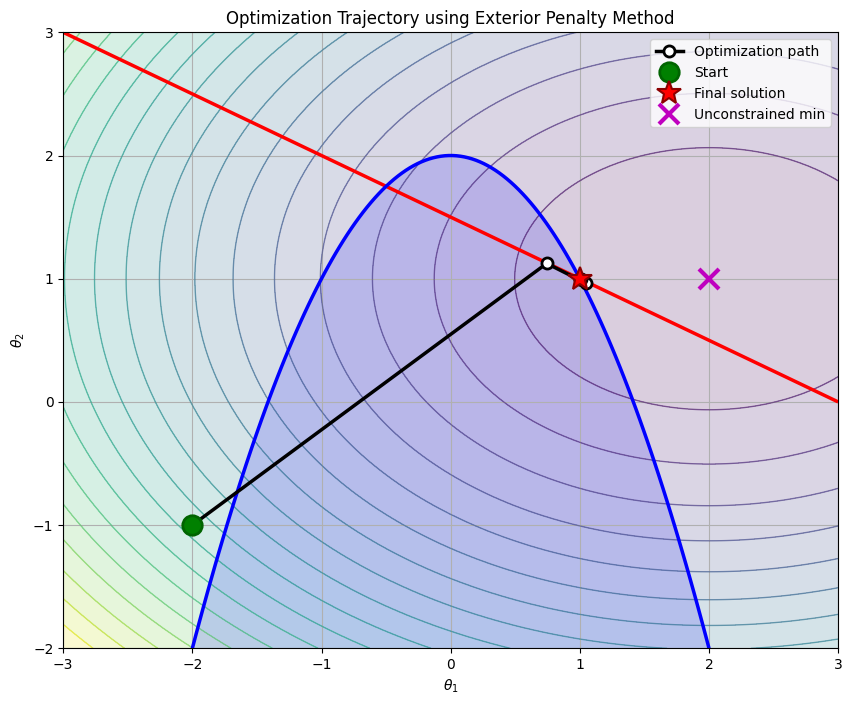

In [23]:
grid_x, grid_y = torch.meshgrid(torch.linspace(-3, 3, 200), torch.linspace(-2, 3, 200), indexing='ij')
grid_theta = torch.stack([grid_x.flatten(), grid_y.flatten()], dim=1)

with torch.no_grad():
    Z_obj = objective(grid_theta).reshape(200, 200)
    Z_eq = eq_constraint(grid_theta).reshape(200, 200)
    Z_ineq = ineq_constraint(grid_theta).reshape(200, 200)

plt.figure(figsize=(10, 8))

# TODO: Plot objective contours
contour_levels = np.linspace(Z_obj.min().item(), Z_obj.max().item(), 20)
plt.contour(grid_x.numpy(), grid_y.numpy(), Z_obj.numpy(), levels=contour_levels, cmap='viridis', alpha=0.6, linewidths=1)
plt.contourf(grid_x.numpy(), grid_y.numpy(), Z_obj.numpy(), levels=contour_levels, cmap='viridis', alpha=0.2)

# TODO: Plot equality constraint line
plt.contour(grid_x.numpy(), grid_y.numpy(), Z_eq.numpy(), levels=[0], colors='red', linewidths=2.5, linestyles='-', label='$h(\\theta) = 0$ (equality)')

# TODO: Shade inequality constraint feasible region
plt.contourf(grid_x.numpy(), grid_y.numpy(), Z_ineq.numpy(), levels=[-1000, 0], colors='blue', alpha=0.15)
plt.contour(grid_x.numpy(), grid_y.numpy(), Z_ineq.numpy(), levels=[0], colors='blue', linewidths=2.5, linestyles='-', label='$g(\\theta) = 0$ (inequality)')

# TODO: Overlay optimization trajectory sequence
traj_np = trajectory.numpy()
plt.plot(traj_np[:, 0], traj_np[:, 1], 'ko-', linewidth=2.5, markersize=8,  markerfacecolor='white', markeredgewidth=2, label='Optimization path', zorder=5)


plt.plot(traj_np[0, 0], traj_np[0, 1], 'go', markersize=14, markeredgewidth=2, markeredgecolor='darkgreen', label='Start', zorder=6)
plt.plot(traj_np[-1, 0], traj_np[-1, 1], 'r*', markersize=18, markeredgewidth=1.5, markeredgecolor='darkred', label='Final solution', zorder=6)
plt.plot(2, 1, 'mx', markersize=14, markeredgewidth=3, label='Unconstrained min', zorder=6)


plt.title("Optimization Trajectory using Exterior Penalty Method")
plt.xlabel(r"$\theta_1$")
plt.ylabel(r"$\theta_2$")
plt.xlim(-3, 3)
plt.ylim(-2, 3)
plt.legend()
plt.grid(True)
plt.show()

## 4.5 Analytical Questions

**Question 1:** Compare your final computational coordinate with the exact $\theta^*$ you found using the analytical KKT conditions in Section 4.1. Do they match? How does the optimizer behave regarding the inequality constraint—does it stop inside the region, or ride exactly along the boundary?

*The final computational solution closely matches the exact solution $θ^∗=(1,1)$ obtained from the analytical KKT conditions in Section 4.1. The optimizer rides exactly along the boundary of the inequality constraint $g(\theta_1, \theta_2) = \theta_1^2 + \theta_2 - 2 \le 0$, meaning the constraint is active at the optimal point. This behavior is expected because the unconstrained minimum at (2,1) lies outside the feasible region, forcing the optimizer to move along the constraint boundary to find the closest feasible point that minimizes the objective.*

*The penalty method successfully drives the solution toward this boundary as rho increases, with the equality constraint $h(\theta_1, \theta_2) = \theta_1 + 2\theta_2 - 3 = 0$ also satisfied. The trajectory visualization confirms that the optimizer does not stop in the interior of the feasible region but instead converges to the boundary where both constraints are active.*

**Question 2:** Observe the Hessian matrix of the unconstrained penalized function $\nabla^2 \mathcal{L}_{penalty}$ mathematically. As $\rho \to \infty$, what happens to the condition number of this matrix? Consequently, why did we have to use an iterative schedule rather than immediately setting $\rho = 100,000$ and running Adam once?

*As $\rho \to \infty$, the Hessian matrix becomes increasingly ill-conditioned, with its condition number growing proportionally to rho. This occurs because the penalty terms 
$ρh(θ)^2$ and $ρmax(0,g(θ))^2$ contribute second-order terms scaled by 𝜌 to the Hessian, creating steep valleys in the loss landscape near the constraint boundaries. When 𝜌 is extremely large (e.g., 𝜌=100,000), the Hessian has vastly different eigenvalues—some very large (corresponding to directions perpendicular to constraints) and some relatively small (tangent to constraints)—making gradient-based optimization unstable and slow to converge. The iterative schedule gradually increases 𝜌, allowing the optimizer to first find an approximate solution with a well-conditioned problem at small 𝜌, then refine it progressively as 𝜌 grows. This warm-start strategy prevents the optimizer from getting stuck in poorly scaled regions and ensures stable convergence to the constrained optimum.*